<a href="https://colab.research.google.com/github/ortizo-117/BMEG_591Q_group_project/blob/master/MLiM_Notebook2_COVID_AlexNet_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML in Medicine — Workshop 2 Notebook 2 (PyTorch)
## COVID vs Normal chest X-ray classification with **AlexNet transfer learning**

**Goal:** use a pretrained CNN backbone (**AlexNet**) and fine-tune it for a 2-class medical task.

**Folder structure expected (ImageFolder style):**
```
data/
  train/
    covid/
      *.png
    normal/
      *.png
  val/
    covid/
      *.png
    normal/
      *.png
```

This notebook includes:
- transfer learning with AlexNet
- freeze/unfreeze experiments
- ROC-AUC + confusion matrix + sensitivity/specificity
- a simple saliency visualization (input gradients)


> Note: Chest X-rays are grayscale. AlexNet expects 3-channel images, so we repeat the channel.


In [ ]:

# Cell 1 — Imports and setup
import os
import math
import random
from typing import Dict, Tuple

import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision import models

import matplotlib.pyplot as plt

# Reproducibility settings
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


/Users/hfarahani/miniconda3/envs/torch/lib/python3.10/site-packages/torchvision/io/image.py:14: UserWarning: Failed to load image Python extension: 'dlopen(/Users/hfarahani/miniconda3/envs/torch/lib/python3.10/site-packages/torchvision/image.so, 0x0006): Library not loaded: @rpath/libjpeg.9.dylib
  Referenced from: <0B7EB158-53DC-3403-8A49-22178CAB4612> /Users/hfarahani/miniconda3/envs/torch/lib/python3.10/site-packages/torchvision/image.so
  Reason: tried: '/Users/hfarahani/miniconda3/envs/torch/lib/python3.10/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/Users/hfarahani/miniconda3/envs/torch/lib/python3.10/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/Users/hfarahani/miniconda3/envs/torch/lib/python3.10/lib-dynload/../../libjpeg.9.dylib' (no such file), '/Users/hfarahani/miniconda3/envs/torch/bin/../lib/libjpeg.9.dylib' (no such file)'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Othe

device(type='cpu')

## Point this notebook to your dataset

**Task:** Set `DATA_DIR` to the folder that contains `train/` and `val/`.


In [ ]:

# Cell 2 — Dataset path (EDIT THIS)
DATA_DIR = "data"  # ✅ change me

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")

assert os.path.isdir(TRAIN_DIR), f"Train directory not found: {TRAIN_DIR}"
assert os.path.isdir(VAL_DIR), f"Val directory not found: {VAL_DIR}"

print("Train dir:", TRAIN_DIR)
print("Val dir:", VAL_DIR)


Train dir: data/train
Val dir: data/val


## Transforms (AlexNet-style)

AlexNet was trained on ImageNet. The common recipe is:
- resize to **224×224** (AlexNet originally used 227×227; 224 works fine in torchvision)
- normalize with ImageNet mean/std

Because X-rays are grayscale, we:
1) convert to **1 channel**
2) then **repeat to 3 channels** so AlexNet can accept it.

🔎 **Question:** Why might ImageNet normalization still "work" for X-rays even though the domain is different?


In [ ]:

# Cell 3 — Transforms
IMG_SIZE = 224  # Task later: try 227

# ImageNet normalization stats (used by pretrained models)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

def to_3ch(x: torch.Tensor) -> torch.Tensor:
    # x is shape (1,H,W) after Grayscale+ToTensor.
    # Repeat to (3,H,W) for AlexNet.
    return x.repeat(3, 1, 1)

train_tfms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Lambda(to_3ch),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_tfms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Lambda(to_3ch),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


In [ ]:

# Cell 4 — Datasets and loaders
train_ds = ImageFolder(TRAIN_DIR, transform=train_tfms)
val_ds   = ImageFolder(VAL_DIR,   transform=val_tfms)

print("Class-to-index mapping:", train_ds.class_to_idx)
class_names = train_ds.classes

BATCH_SIZE = 32  # AlexNet is heavier; smaller batch helps on modest GPUs/CPUs
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("Batch x shape:", xb.shape, "Batch y shape:", yb.shape)


Class-to-index mapping: {'covid': 0, 'normal': 1}
Batch x shape: torch.Size([32, 3, 224, 224]) Batch y shape: torch.Size([32])


## Quick inspection

**Task:** Visualize a few images (after undoing ImageNet normalization).

**Question:** Do you see "shortcuts" like text markers, borders, or systematic contrast differences between classes?


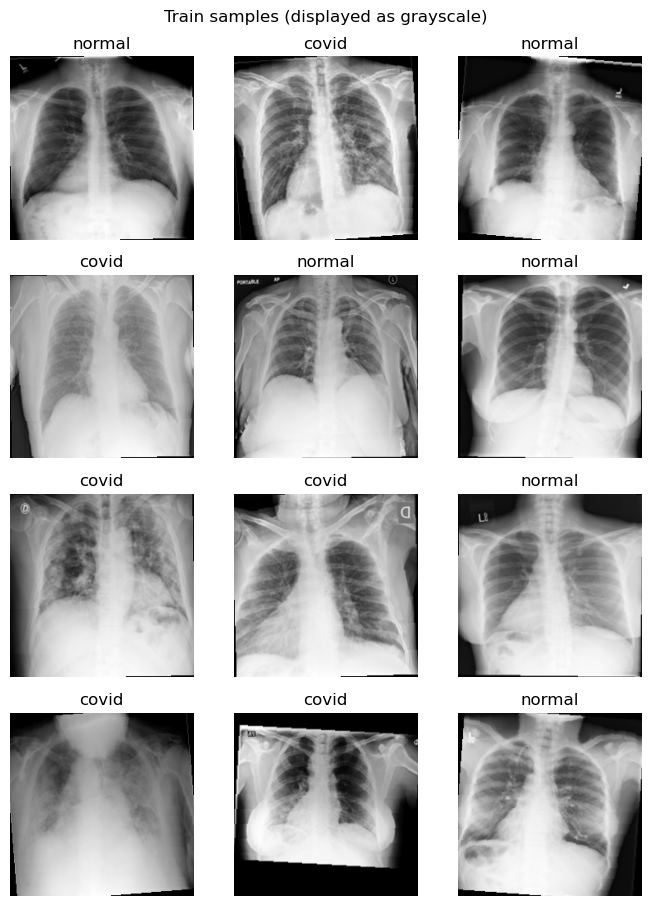

In [ ]:

# Cell 5 — Visualization helpers
def denorm_imagenet(x: torch.Tensor) -> torch.Tensor:
    # Undo ImageNet normalization for display only.
    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std  = torch.tensor(IMAGENET_STD).view(3,1,1)
    return x.cpu() * std + mean

def show_grid(batch_x, batch_y, class_names, n=12, title="Samples"):
    n = min(n, batch_x.size(0))
    cols = int(math.sqrt(n))
    rows = int(math.ceil(n / cols))
    plt.figure(figsize=(2.3*cols, 2.3*rows))
    for i in range(n):
        plt.subplot(rows, cols, i+1)
        img = denorm_imagenet(batch_x[i]).permute(1,2,0).numpy()
        # Display as grayscale using the first channel
        plt.imshow(img[...,0], cmap="gray")
        plt.title(class_names[int(batch_y[i])])
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_grid(xb, yb, class_names, n=12, title="Train samples (displayed as grayscale)")


## Transfer learning with AlexNet

We will:
1) Load pretrained AlexNet
2) Replace the last layer to output **2 classes**
3) First, **freeze** the convolutional backbone and train only the classifier head
4) Then optionally **fine-tune** the last convolutional block

**Task:** Explain (in your own words) why freezing is useful when you have limited medical data.


In [ ]:

# Cell 6 — Load pretrained AlexNet and replace classifier head
# torchvision API differs across versions; we handle both patterns.

def get_alexnet_pretrained(num_classes: int):
    try:
        # Newer torchvision
        weights = models.AlexNet_Weights.DEFAULT
        model = models.alexnet(weights=weights)
    except Exception:
        # Older torchvision
        model = models.alexnet(pretrained=True)

    # Replace final layer: classifier[6] is the last Linear in AlexNet
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, num_classes)
    return model

model = get_alexnet_pretrained(num_classes=len(class_names)).to(device)
model


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [ ]:

# Cell 7 — Freeze backbone (features) and train only classifier
def set_trainable(module: nn.Module, trainable: bool):
    for p in module.parameters():
        p.requires_grad = trainable

# Freeze convolutional feature extractor
set_trainable(model.features, False)

# Ensure classifier is trainable
set_trainable(model.classifier, True)

# Sanity check: count trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
all_params = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable_params:,} / {all_params:,} ({100*trainable_params/all_params:.2f}%)")


Trainable params: 54,542,338 / 57,012,034 (95.67%)


## Training loop (with probabilities for ROC-AUC)

We compute:
- loss + accuracy
- probabilities for the COVID class to compute ROC-AUC

 **Task:** Identify which numeric label corresponds to COVID using `train_ds.class_to_idx`.


In [ ]:

# Cell 8 — Train/eval helpers
@torch.no_grad()
def evaluate(model, loader, criterion) -> Tuple[float, float, np.ndarray, np.ndarray]:
    # Returns: avg_loss, accuracy, y_true (N,), y_prob (N,2)
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    y_true_all = []
    y_prob_all = []

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        total_correct += (preds == y).sum().item()
        total += x.size(0)

        probs = torch.softmax(logits, dim=1)  # (B,2)
        y_true_all.append(y.detach().cpu().numpy())
        y_prob_all.append(probs.detach().cpu().numpy())

    y_true_all = np.concatenate(y_true_all, axis=0)
    y_prob_all = np.concatenate(y_prob_all, axis=0)
    return total_loss / total, total_correct / total, y_true_all, y_prob_all

def train_model(model, train_loader, val_loader, epochs=5, lr=1e-3, weight_decay=1e-4):
    criterion = nn.CrossEntropyLoss()

    # Only optimize parameters that are marked trainable
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, running_correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == y).sum().item()
            total += x.size(0)

        train_loss = running_loss / total
        train_acc = running_correct / total
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch:02d}/{epochs} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}")

    return history

def plot_curves(history: Dict[str, list]):
    plt.figure(figsize=(7,4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Loss curves")
    plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(history["train_acc"], label="train_acc")
    plt.plot(history["val_acc"], label="val_acc")
    plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy curves")
    plt.show()


## Train the classifier head (frozen backbone)

✅ **Task:** Try `epochs=8` and compare with `epochs=3`.

🔎 **Question:** Why does this often converge faster than training a CNN from scratch?


Epoch 01/5 | train_loss=0.9280 train_acc=0.684 | val_loss=0.5802 val_acc=0.710
Epoch 02/5 | train_loss=0.4391 train_acc=0.809 | val_loss=0.2952 val_acc=0.887
Epoch 03/5 | train_loss=0.2859 train_acc=0.886 | val_loss=0.3612 val_acc=0.851
Epoch 04/5 | train_loss=0.3090 train_acc=0.869 | val_loss=0.2205 val_acc=0.919
Epoch 05/5 | train_loss=0.2489 train_acc=0.896 | val_loss=0.2677 val_acc=0.883


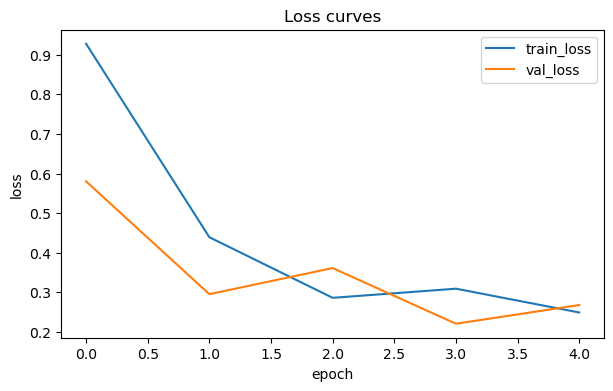

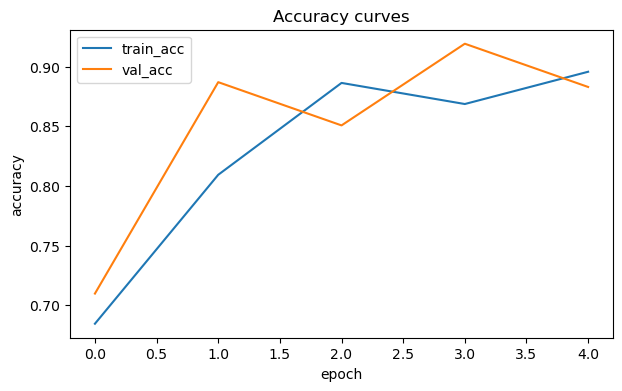

In [ ]:

# Cell 9 — Train head only
history_head = train_model(model, train_loader, val_loader, epochs=5, lr=1e-3, weight_decay=1e-4)
plot_curves(history_head)


## Metrics: confusion matrix + sensitivity/specificity + ROC-AUC

We treat **COVID** as the positive class.

**Task:** Set `COVID_LABEL` correctly using `train_ds.class_to_idx`.


In [ ]:

# Cell 10 — Metrics (no sklearn required)
@torch.no_grad()
def confusion_matrix(model, loader, num_classes=2) -> np.ndarray:
    model.eval()
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        preds = logits.argmax(dim=1)
        for t, p in zip(y.view(-1), preds.view(-1)):
            cm[t.long(), p.long()] += 1
    return cm.cpu().numpy()

def metrics_binary_from_cm(cm: np.ndarray, positive_label: int) -> Dict[str, float]:
    assert cm.shape == (2, 2)
    if positive_label == 1:
        tn, fp = cm[0,0], cm[0,1]
        fn, tp = cm[1,0], cm[1,1]
    else:
        tn, fp = cm[1,1], cm[1,0]
        fn, tp = cm[0,1], cm[0,0]
    acc = (tp + tn) / (tp + tn + fp + fn + 1e-12)
    precision = tp / (tp + fp + 1e-12)
    sensitivity = tp / (tp + fn + 1e-12)
    specificity = tn / (tn + fp + 1e-12)
    return {
        "accuracy": float(acc),
        "precision": float(precision),
        "sensitivity_recall": float(sensitivity),
        "specificity": float(specificity),
        "tp": float(tp), "tn": float(tn), "fp": float(fp), "fn": float(fn),
    }

def roc_auc_score_manual(y_true: np.ndarray, y_score: np.ndarray) -> float:
    # Computes ROC-AUC via rank statistic (equivalent to Mann-Whitney U).
    y_true = y_true.astype(np.int64)
    order = np.argsort(y_score)
    ranks = np.empty_like(order, dtype=np.float64)
    ranks[order] = np.arange(1, len(y_score) + 1)  # ranks 1..N

    pos = (y_true == 1)
    n_pos = pos.sum()
    n_neg = len(y_true) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")

    sum_ranks_pos = ranks[pos].sum()
    auc = (sum_ranks_pos - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    return float(auc)

criterion = nn.CrossEntropyLoss()
val_loss, val_acc, y_true, y_prob = evaluate(model, val_loader, criterion)

COVID_LABEL = train_ds.class_to_idx.get("covid", 0)  # verify mapping
y_true_bin = (y_true == COVID_LABEL).astype(np.int64)
y_score = y_prob[:, COVID_LABEL]  # probability assigned to COVID label

cm = confusion_matrix(model, val_loader, num_classes=len(class_names))
metrics = metrics_binary_from_cm(cm, positive_label=COVID_LABEL)
auc = roc_auc_score_manual(y_true_bin, y_score)

print("Val loss:", val_loss, "Val acc:", val_acc)
print("Confusion matrix (rows=true, cols=pred):\n", cm)
print("Metrics:", metrics)
print("ROC-AUC:", auc)


Val loss: 0.26768150060407575 Val acc: 0.8830645161290323
Confusion matrix (rows=true, cols=pred):
 [[ 98  26]
 [  3 121]]
Metrics: {'accuracy': 0.8830645161290287, 'precision': 0.9702970297029607, 'sensitivity_recall': 0.7903225806451549, 'specificity': 0.9758064516128954, 'tp': 98.0, 'tn': 121.0, 'fp': 3.0, 'fn': 26.0}
ROC-AUC: 0.9730098855359001


## Fine-tuning: unfreeze the last conv block

Now we:
- unfreeze **some** of the feature extractor
- train with a smaller learning rate

**Task:** Compare performance when you fine-tune:
1) only classifier (already done)
2) classifier + last conv block
3) full network (optional; more overfitting risk)


Trainable params: 56,681,346 / 57,012,034 (99.42%)
Epoch 01/3 | train_loss=0.2648 train_acc=0.891 | val_loss=0.1732 val_acc=0.940
Epoch 02/3 | train_loss=0.1509 train_acc=0.943 | val_loss=0.3000 val_acc=0.871
Epoch 03/3 | train_loss=0.1490 train_acc=0.935 | val_loss=0.1668 val_acc=0.948


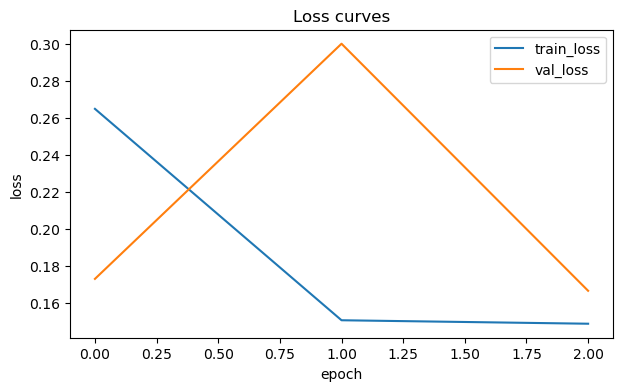

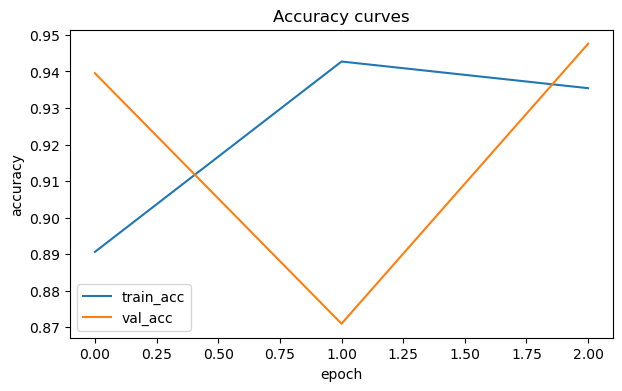

In [ ]:

# Cell 11 — Unfreeze last conv block (optional fine-tuning)
# AlexNet features is a Sequential of layers. We'll unfreeze the last few layers.

set_trainable(model.features, False)

for i, layer in enumerate(model.features):
    if i >= 6:
        set_trainable(layer, True)

set_trainable(model.classifier, True)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
all_params = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {trainable_params:,} / {all_params:,} ({100*trainable_params/all_params:.2f}%)")

history_ft = train_model(model, train_loader, val_loader, epochs=3, lr=1e-4, weight_decay=1e-4)
plot_curves(history_ft)


## Error analysis: visualize misclassified validation images

 **Task:** Look for patterns:
- low-quality scans?
- border/text marker correlation?
- missed positives (false negatives) vs false alarms (false positives)?

**Question:** What *non-medical* cues could the model be using?


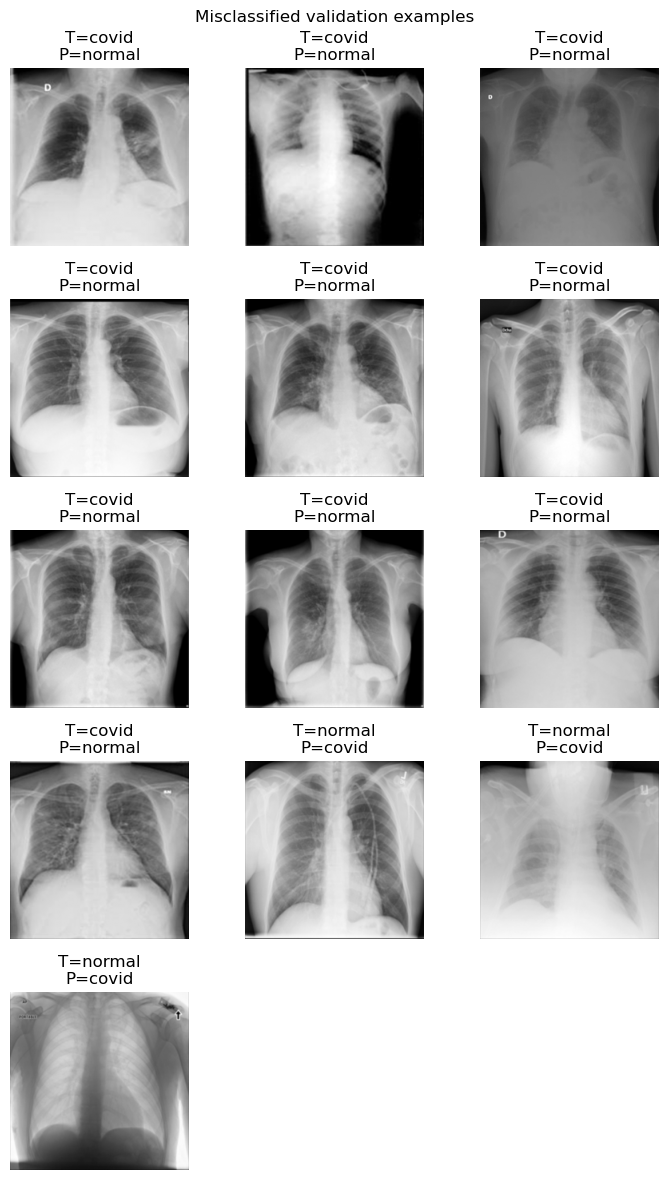

In [ ]:

# Cell 12 — Misclassifications
def denorm_imagenet_gray(img3: torch.Tensor) -> np.ndarray:
    img = denorm_imagenet(img3).permute(1,2,0).numpy()
    return np.clip(img[...,0], 0, 1)

@torch.no_grad()
def get_misclassified(model, loader, max_items=16):
    model.eval()
    bad = []
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        preds = logits.argmax(dim=1)
        wrong = preds != y
        if wrong.any():
            xw = x[wrong].cpu()
            yw = y[wrong].cpu()
            pw = preds[wrong].cpu()
            for i in range(len(yw)):
                bad.append((xw[i], int(yw[i]), int(pw[i])))
                if len(bad) >= max_items:
                    return bad
    return bad

def show_misclassified(bad_list, class_names, n=16, title="Misclassified"):
    n = min(n, len(bad_list))
    if n == 0:
        print("No misclassifications found (or max_items too small).")
        return
    cols = int(math.sqrt(n))
    rows = int(math.ceil(n / cols))
    plt.figure(figsize=(2.4*cols, 2.4*rows))
    for i in range(n):
        img, ytrue, ypred = bad_list[i]
        img_disp = denorm_imagenet_gray(img)
        plt.subplot(rows, cols, i+1)
        plt.imshow(img_disp, cmap="gray")
        plt.title(f"T={class_names[ytrue]}\nP={class_names[ypred]}")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

bad = get_misclassified(model, val_loader, max_items=16)
show_misclassified(bad, class_names, n=16, title="Misclassified validation examples")


## Simple saliency map (input gradients)

This is a lightweight interpretability demo:
- take a single image
- compute gradient of the COVID score wrt input pixels
- visualize gradient magnitude

**Task:** Try one correctly classified and one misclassified image. Compare saliency.


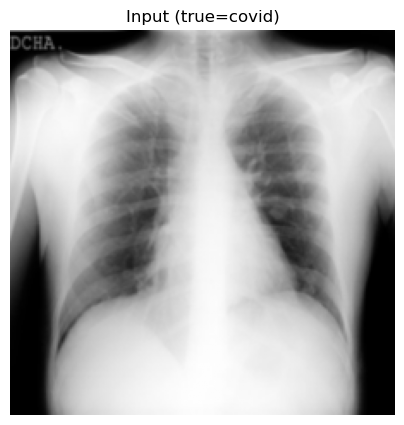

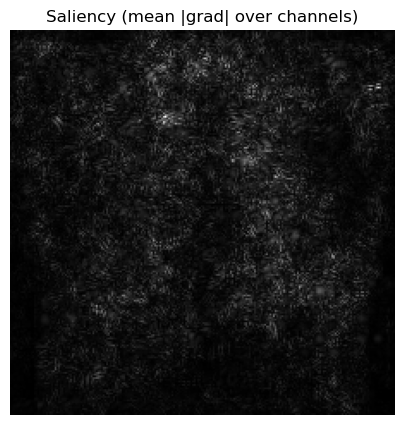

In [ ]:

# Cell 13 — Saliency by input gradients (Grad-CAM-lite)
def compute_saliency(model, img: torch.Tensor, target_label: int) -> np.ndarray:
    model.eval()
    x = img.unsqueeze(0).to(device)
    x.requires_grad_(True)

    logits = model(x)
    score = logits[0, target_label]
    score.backward()

    grad = x.grad.detach().abs().squeeze(0)  # (3,H,W)
    sal = grad.mean(dim=0).cpu().numpy()     # (H,W)
    sal = sal / (sal.max() + 1e-12)
    return sal

img, ytrue = val_ds[0]
sal = compute_saliency(model, img, target_label=COVID_LABEL)
img_disp = denorm_imagenet_gray(img)

plt.figure(figsize=(5,5))
plt.imshow(img_disp, cmap="gray")
plt.title(f"Input (true={class_names[ytrue]})")
plt.axis("off")
plt.show()

plt.figure(figsize=(5,5))
plt.imshow(sal, cmap="gray")
plt.title("Saliency (mean |grad| over channels)")
plt.axis("off")
plt.show()


## Wrap-up questions (short answers)

1) When did transfer learning help most: **small data** or **large data**?
2) Why might a model trained on ImageNet still provide useful low-level features for X-rays?
3) What are the biggest risks of deploying this in real clinical settings?


## Optional: Save the trained model

**Task:** Uncomment and save weights, then load them later.


In [ ]:

# Cell 14 — Save / load weights (optional)
# torch.save(model.state_dict(), "alexnet_covid_vs_normal.pt")
# model2 = get_alexnet_pretrained(num_classes=len(class_names)).to(device)
# model2.load_state_dict(torch.load("alexnet_covid_vs_normal.pt", map_location=device))
# model2.eval()
